# Classify Customers into different Clusters for a shop? 
### Daily
### Weekend
### Promotion

In [58]:
import pandas as pd
import numpy as np
data={
'CustomerID':np.arange(1,101),
'Age':np.random.randint(10,65,100),
'Average_Spend':(np.random.random(100)*45)+5,
'Visits_per_week':np.random.randint(1,7,100),
'Promotion_Interest':np.random.randint(1,11,100)}
df=pd.DataFrame(data)

In [59]:
df.head()

,CustomerID,Age,Average_Spend,Visits_per_week,Promotion_Interest
0,1,15,34.196071,2,6
1,2,16,37.649631,2,10
2,3,64,33.374172,4,5
3,4,52,19.275346,1,1
4,5,56,47.725586,3,8


<Axes: >

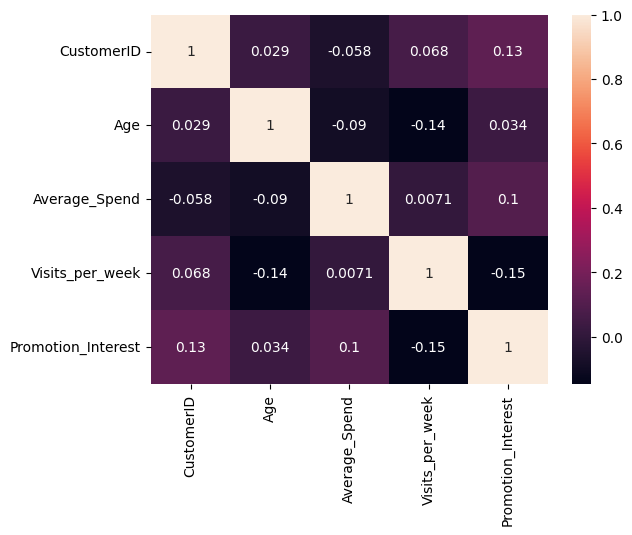

In [60]:
import seaborn as sns
corr=df.corr()
sns.heatmap(corr,annot=True)

In [61]:
df.drop(columns=['CustomerID'],inplace=True)

In [62]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
pca=PCA(n_components=2)
input_x=scaler.fit_transform(df)
input_x=pca.fit_transform(input_x)

In [63]:
import dill
with open('scaler.pkl','wb') as f:
    dill.dump(scaler,f)

In [64]:
import dill
with open('pca.pkl','wb') as f:
    dill.dump(pca,f)

In [65]:
input_x.shape

(100, 2)

In [66]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,12):
    kmean=KMeans(n_clusters=i,init='k-means++')
    kmean.fit(input_x)
    wcss.append(kmean.inertia_)
print(wcss)

[234.44315825680826, 149.34856207904454, 99.70107610434972, 69.80620519562996, 54.70715788961212, 40.90640360757751, 35.7345218752819, 33.1890780682039, 28.326447874402554, 25.621737060103158, 23.695516588108106]


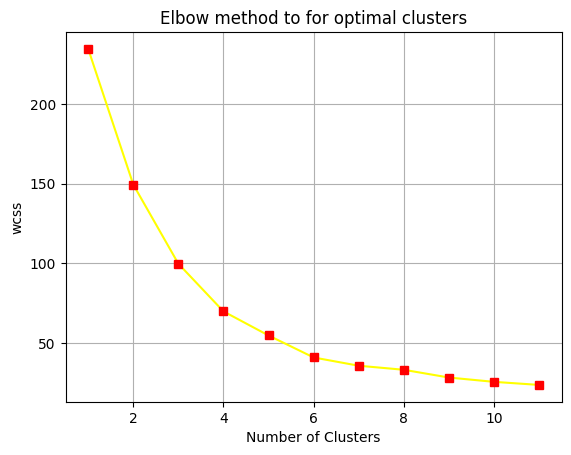

In [67]:
import matplotlib.pyplot as plt
plt.plot(range(1,12),wcss,marker='s',markerfacecolor='red',markeredgecolor='red',color='yellow')
plt.xlabel('Number of Clusters')
plt.ylabel('wcss')
plt.title('Elbow method to for optimal clusters')
plt.grid()
plt.show()

# To validate how many clusters we must have? 

In [68]:
from kneed import KneeLocator
knee=KneeLocator(range(1,12),wcss,curve='convex',direction='decreasing')
knee.elbow

np.int64(4)

In [69]:
from sklearn.metrics import silhouette_score
scores=[]
for k in range(2,12):
    kmean=KMeans(n_clusters=k,init='k-means++')
    kmean.fit(input_x)
    score=silhouette_score(input_x,labels=kmean.labels_)
    scores.append(score)
print(scores)

[0.326497212021576, 0.3398381592650969, 0.34228186287741313, 0.3936977939435846, 0.4192643391288714, 0.3956192922968615, 0.3810282060951936, 0.3604302625265624, 0.3488061634323566, 0.34754651986224805]


#### According to silhoutte_score best number of clusters is 3 and kneeLocator tells 4 so let's consider as 3 as per the problem statement

In [70]:
kmean=KMeans(n_clusters=3,init='k-means++',random_state=42)
y_pred=kmean.fit_predict(input_x)

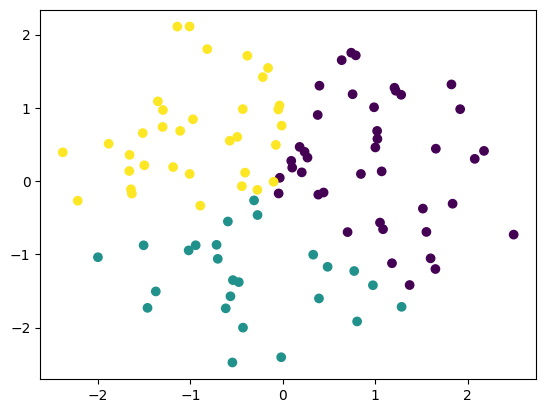

In [71]:
import matplotlib.pyplot as plt
plt.scatter(input_x[:,0],input_x[:,1],c=y_pred)
plt.show()

In [72]:
import dill
with open('model.pkl','wb') as f:
    dill.dump(kmean,f)